In [12]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df=pd.read_csv("maize_yield_rwanda_rw.csv")

In [14]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_report)

,Missing Values,Percentage
record_id,0,0.00
year,0,0.00
season,0,0.00
province,0,0.00
district,0,0.00
altitude_m,0,0.00
rainfall_mm,11,0.77
avg_temp_c,0,0.00
soil_ph,14,0.98
soil_type,0,0.00


In [15]:
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

print("Duplicate record IDs:",
      df["record_id"].duplicated().sum())

Total duplicate records: 0
Duplicate record IDs: 0


In [16]:
print(df.dtypes)

record_id                object
year                      int64
season                   object
province                 object
district                 object
altitude_m                int64
rainfall_mm             float64
avg_temp_c              float64
soil_ph                 float64
soil_type                object
seed_variety             object
farming_practice         object
npk_kg_ha               float64
urea_kg_ha              float64
manure_t_ha             float64
plant_density_per_ha      int64
farm_area_ha            float64
irrigation               object
pest_incidence_index    float64
yield_t_ha              float64
dtype: object


In [17]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 record_id
record_id
RW-MZ-01426    1
RW-MZ-00001    1
RW-MZ-01410    1
RW-MZ-01409    1
RW-MZ-01408    1
              ..
RW-MZ-00007    1
RW-MZ-00006    1
RW-MZ-00005    1
RW-MZ-00004    1
RW-MZ-00003    1
Name: count, Length: 1426, dtype: int64

 season
season
A    600
B    600
C    226
Name: count, dtype: int64

 province
province
Southern    388
Western     348
Eastern     328
Northern    230
Kigali      132
Name: count, dtype: int64

 district
district
Karongi       56
Nyanza        54
Nyamasheke    52
Huye          52
Gicumbi       50
Kirehe        50
Ruhango       50
Nyabihu       50
Rutsiro       50
Rulindo       48
Kayonza       48
Nyagatare     48
Gisagara      48
Kamonyi       48
Rwamagana     48
Rusizi        48
Nyamagabe     48
Ngororero     46
Gatsibo       46
Gakenke       46
Bugesera      46
Nyarugenge    46
Rubavu        46
Musanze       44
Muhanga       44
Kicukiro      44
Nyaruguru     44
Gasabo        42
Burera        42
Ngoma         42
Name: count, dtype: int64


In [18]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outlier_report = pd.DataFrame({
    "Outliers": (
        (df[numerical_columns] < lower_limit) |
        (df[numerical_columns] > upper_limit)
    ).sum()
})

display(outlier_report)

,Outliers
year,0
altitude_m,0
rainfall_mm,0
avg_temp_c,0
soil_ph,10
npk_kg_ha,0
urea_kg_ha,0
manure_t_ha,6
plant_density_per_ha,0
farm_area_ha,75


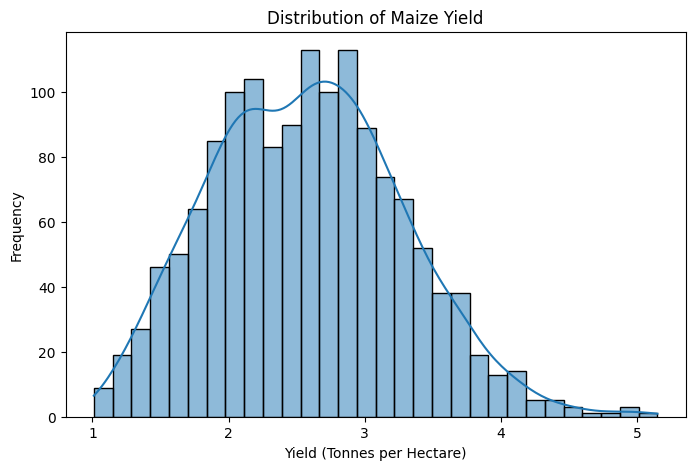

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["yield_t_ha"],
    bins=30,
    kde=True
)

plt.title("Distribution of Maize Yield")
plt.xlabel("Yield (Tonnes per Hectare)")
plt.ylabel("Frequency")

plt.show()

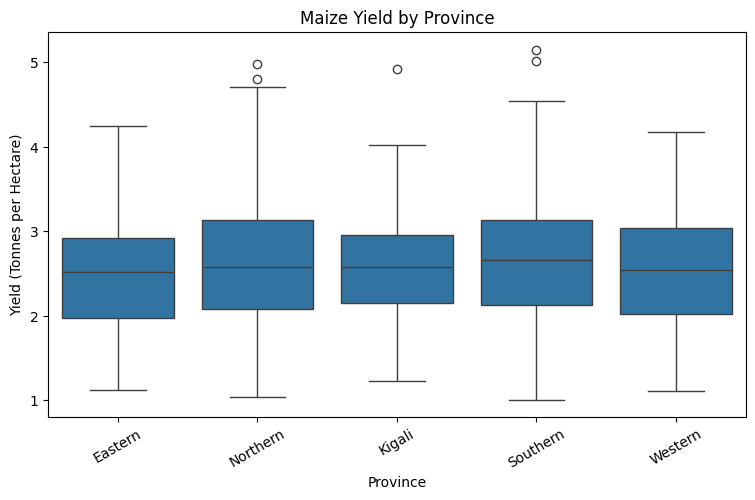

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="province",
    y="yield_t_ha"
)

plt.title("Maize Yield by Province")
plt.xlabel("Province")
plt.ylabel("Yield (Tonnes per Hectare)")
plt.xticks(rotation=30)

plt.show()

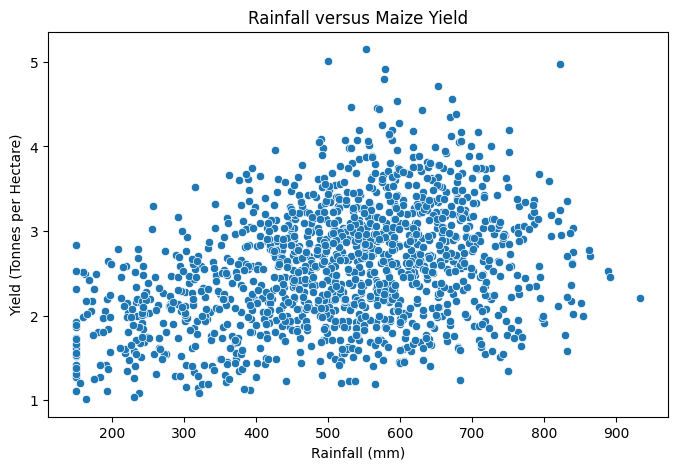

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="rainfall_mm",
    y="yield_t_ha"
)

plt.title("Rainfall versus Maize Yield")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (Tonnes per Hectare)")

plt.show()

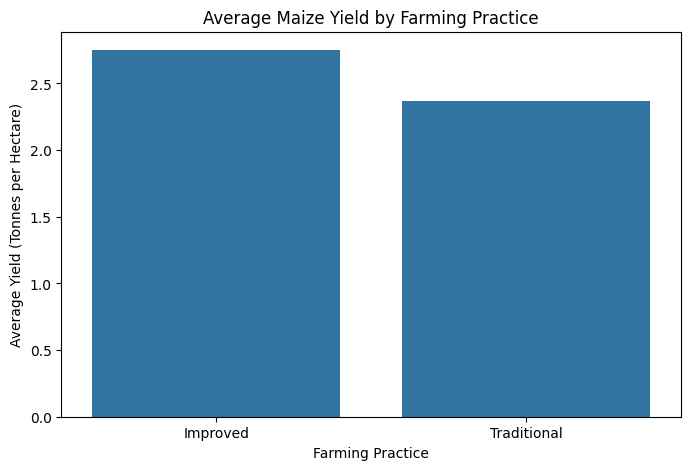

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="farming_practice",
    y="yield_t_ha",
    errorbar=None
)

plt.title("Average Maize Yield by Farming Practice")
plt.xlabel("Farming Practice")
plt.ylabel("Average Yield (Tonnes per Hectare)")

plt.show()

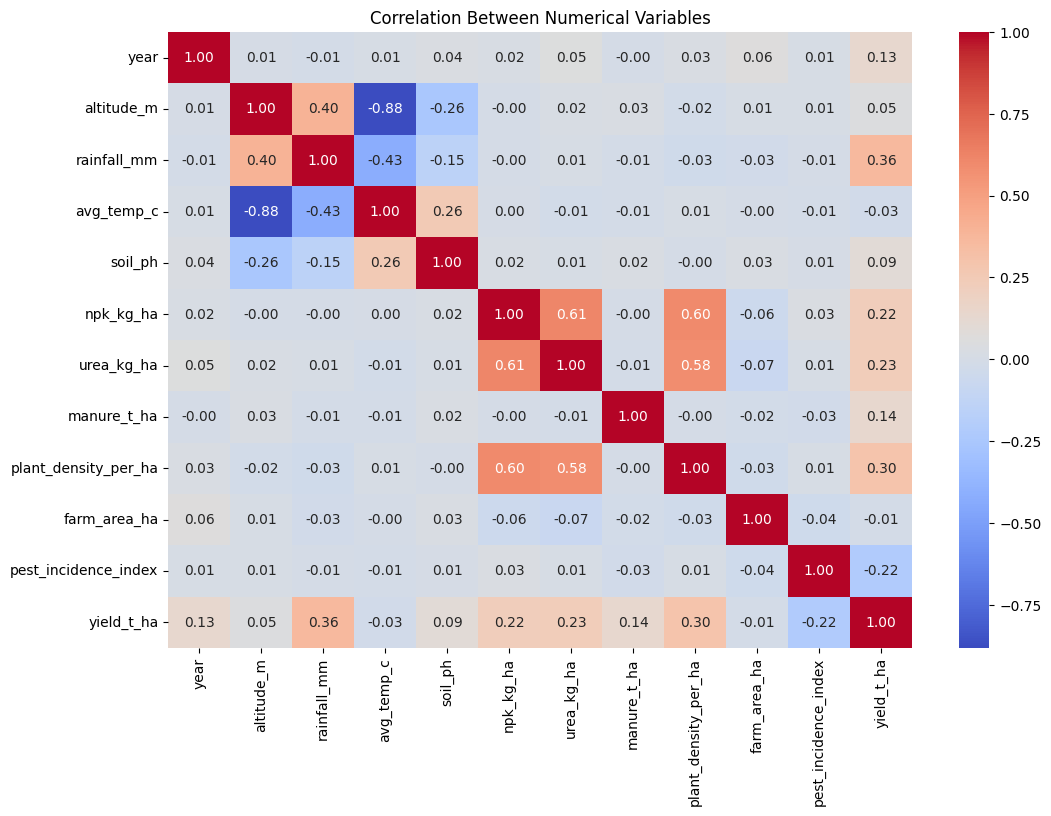

In [23]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")

plt.show()

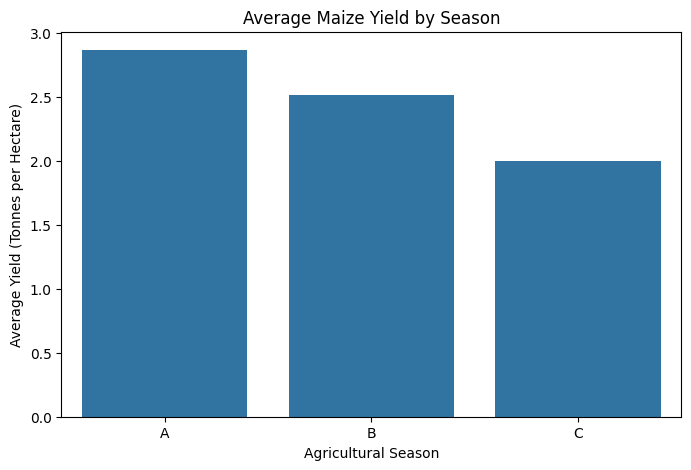

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="season",
    y="yield_t_ha",
    errorbar=None
)

plt.title("Average Maize Yield by Season")
plt.xlabel("Agricultural Season")
plt.ylabel("Average Yield (Tonnes per Hectare)")

plt.show()

In [28]:
import os

# Create the docs folder if it does not exist
os.makedirs("../docs", exist_ok=True)

print("Docs folder is ready!")

Docs folder is ready!


In [29]:
quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

display(quality_report)

quality_report.to_csv(
    "../docs/data_quality_report.csv",
    index=False
)

,Column,Data Type,Missing Values,Unique Values
0,record_id,object,0,1426
1,year,int64,0,10
2,season,object,0,3
3,province,object,0,5
4,district,object,0,30
5,altitude_m,int64,0,680
6,rainfall_mm,float64,11,1225
7,avg_temp_c,float64,0,76
8,soil_ph,float64,14,211
9,soil_type,object,0,5
